<a href="https://colab.research.google.com/github/hlacquement6-dotcom/dog-sitting-operations-analysis/blob/main/dog_sitting_operations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exported pets.csv and care_logs.csv successfully.

--- QUERY 1: TIME BLOCK BOTTLENECKS ---
            time_block  total_visits  avg_duration_mins  avg_delay_mins  \
0    Morning (7-10 AM)           133               38.5             6.5   
1     Evening (5-8 PM)           123               39.0             2.3   
2  Midday (11 AM-2 PM)            79               39.9             2.2   

   pct_delayed  
0         46.6  
1         18.7  
2         15.2   

--- QUERY 2: EFFECTIVE HOURLY RATE BY PET TIER ---
  size_category energy_level  visit_count  avg_mins  avg_hourly_rate
0         Large         High          160      48.1            59.39
1        Medium     Moderate           80      32.4            73.86
2         Small     Moderate           42      29.6            80.70
3         Small          Low           53      29.1            87.48 

--- QUERY 3: PEAK 7-DAY ROLLING WORKLOADS ---
   visit_date  visits  total_active_mins  rolling_7d_avg_mins
0  2026-08-01       6           

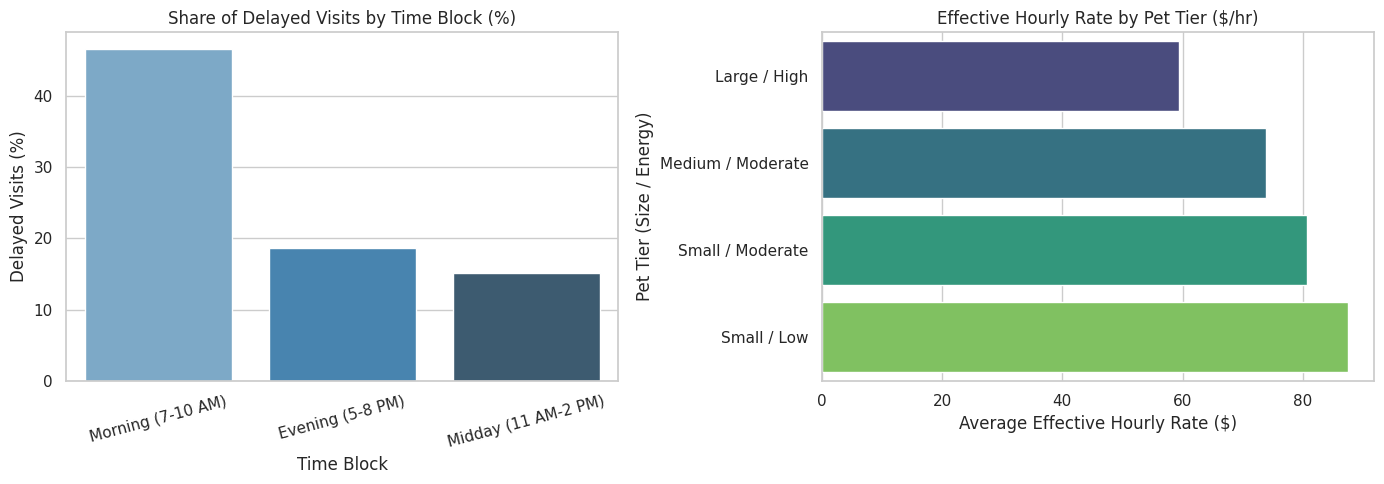

In [2]:
import sqlite3
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Generate Realistic Two-Table Dataset (90 Days)
# ---------------------------------------------------------
np.random.seed(42)

pets_data = [
    (101, 'Cooper', 'Golden Retriever', 'Large', 'High', 0, 45.00),
    (102, 'Bella', 'French Bulldog', 'Small', 'Low', 1, 40.00),
    (103, 'Max', 'German Shepherd', 'Large', 'High', 1, 50.00),
    (104, 'Daisy', 'Beagle', 'Medium', 'Moderate', 0, 35.00),
    (105, 'Charlie', 'Labrador Mix', 'Large', 'High', 0, 42.00),
    (106, 'Luna', 'Dachshund', 'Small', 'Moderate', 1, 38.00),
    (107, 'Rocky', 'Boxer', 'Large', 'High', 0, 45.00),
    (108, 'Milo', 'Corgi', 'Medium', 'Moderate', 0, 38.00)
]
pets_df = pd.DataFrame(pets_data, columns=[
    'pet_id', 'dog_name', 'breed', 'size_category', 'energy_level', 'requires_meds', 'base_visit_rate'
])

dates = pd.date_range(start='2026-08-01', periods=90, freq='D')
time_blocks = ['Morning (7-10 AM)', 'Midday (11 AM-2 PM)', 'Evening (5-8 PM)']
activities = ['Walk & Exercise', 'Feeding & Meds', 'Drop-In Check']

logs = []
log_id = 1001

for d in dates:
    is_peak_day = d.weekday() in [4, 5, 6]
    daily_visits = np.random.randint(4, 7) if is_peak_day else np.random.randint(2, 5)

    for _ in range(daily_visits):
        pet = pets_df.sample(1).iloc[0]
        block = np.random.choice(time_blocks, p=[0.40, 0.25, 0.35])
        activity = (
            'Feeding & Meds'
            if pet['requires_meds'] == 1 and np.random.rand() < 0.5
            else np.random.choice(activities)
        )

        base_dur = 45 if activity == 'Walk & Exercise' else 25
        energy_add = 15 if pet['energy_level'] == 'High' else 0
        duration = base_dur + energy_add + np.random.randint(-5, 10)

        delay_prob = 0.45 if block == 'Morning (7-10 AM)' else 0.15
        delay = np.random.randint(5, 22) if np.random.rand() < delay_prob else 0

        logs.append((log_id, d.strftime('%Y-%m-%d'), block, pet['pet_id'], activity, duration, delay))
        log_id += 1

logs_df = pd.DataFrame(logs, columns=[
    'log_id', 'visit_date', 'time_block', 'pet_id', 'activity_type', 'duration_minutes', 'delay_minutes'
])

# Export CSVs to Colab's working directory for download/upload to GitHub
pets_df.to_csv('pets.csv', index=False)
logs_df.to_csv('care_logs.csv', index=False)
print("Exported pets.csv and care_logs.csv successfully.\n")

# ---------------------------------------------------------
# 2. Load into SQLite Relational Database
# ---------------------------------------------------------
conn = sqlite3.connect(':memory:')
pets_df.to_sql('pets', conn, index=False)
logs_df.to_sql('care_logs', conn, index=False)

# ---------------------------------------------------------
# 3. Query 1: Operational Bottlenecks by Time Block
# ---------------------------------------------------------
q1 = """
SELECT
    l.time_block,
    COUNT(l.log_id) AS total_visits,
    ROUND(AVG(l.duration_minutes), 1) AS avg_duration_mins,
    ROUND(AVG(l.delay_minutes), 1) AS avg_delay_mins,
    ROUND(SUM(CASE WHEN l.delay_minutes > 0 THEN 1.0 ELSE 0 END) / COUNT(*) * 100, 1) AS pct_delayed
FROM care_logs l
JOIN pets p ON l.pet_id = p.pet_id
GROUP BY l.time_block
ORDER BY avg_delay_mins DESC;
"""
q1_df = pd.read_sql_query(q1, conn)
print("--- QUERY 1: TIME BLOCK BOTTLENECKS ---")
print(q1_df, "\n")

# ---------------------------------------------------------
# 4. Query 2: Effective Hourly Rate by Pet Tier
# ---------------------------------------------------------
q2 = """
WITH visit_economics AS (
    SELECT
        p.size_category,
        p.energy_level,
        p.base_visit_rate,
        l.duration_minutes,
        (p.base_visit_rate / (l.duration_minutes / 60.0)) AS effective_hourly_rate
    FROM care_logs l
    JOIN pets p ON l.pet_id = p.pet_id
)
SELECT
    size_category,
    energy_level,
    COUNT(*) AS visit_count,
    ROUND(AVG(duration_minutes), 1) AS avg_mins,
    ROUND(AVG(effective_hourly_rate), 2) AS avg_hourly_rate
FROM visit_economics
GROUP BY size_category, energy_level
ORDER BY avg_hourly_rate ASC;
"""
q2_df = pd.read_sql_query(q2, conn)
print("--- QUERY 2: EFFECTIVE HOURLY RATE BY PET TIER ---")
print(q2_df, "\n")

# ---------------------------------------------------------
# 5. Query 3: 7-Day Rolling Workload Trend (Window Function)
# ---------------------------------------------------------
q3 = """
WITH daily_minutes AS (
    SELECT
        visit_date,
        COUNT(log_id) AS visits,
        SUM(duration_minutes) AS total_active_mins
    FROM care_logs
    GROUP BY visit_date
)
SELECT
    visit_date,
    visits,
    total_active_mins,
    ROUND(AVG(total_active_mins) OVER (
        ORDER BY visit_date
        ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
    ), 1) AS rolling_7d_avg_mins
FROM daily_minutes
ORDER BY rolling_7d_avg_mins DESC
LIMIT 5;
"""
q3_df = pd.read_sql_query(q3, conn)
print("--- QUERY 3: PEAK 7-DAY ROLLING WORKLOADS ---")
print(q3_df, "\n")

# ---------------------------------------------------------
# 6. Visualizations
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Delay Rate by Time Block
sns.barplot(data=q1_df, x='time_block', y='pct_delayed', hue='time_block', palette='Blues_d', legend=False, ax=axes[0])
axes[0].set_title('Share of Delayed Visits by Time Block (%)')
axes[0].set_xlabel('Time Block')
axes[0].set_ylabel('Delayed Visits (%)')
axes[0].tick_params(axis='x', rotation=15)

# Chart 2: Effective Hourly Rate by Pet Tier
q2_df['pet_tier'] = q2_df['size_category'] + ' / ' + q2_df['energy_level']
sns.barplot(data=q2_df, x='avg_hourly_rate', y='pet_tier', hue='pet_tier', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Effective Hourly Rate by Pet Tier ($/hr)')
axes[1].set_xlabel('Average Effective Hourly Rate ($)')
axes[1].set_ylabel('Pet Tier (Size / Energy)')

plt.tight_layout()
plt.show()